In [1]:
PATH = "Assignment3 Data/"

In [6]:
!pip install torch 
!pip install torchvision

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 619.9/619.9 MB 2.3 MB/s eta 0:00:00m eta 0:00:010:00:04
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 MB 4.7 MB/s eta 0:00:00m eta 0:00:010:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.0/21.0 MB 4.3 MB/s eta 0:00:00m eta 0:00:010:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 MB 4.0 MB/s eta 0:00:00m eta 0:00:010:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.4/168.4 MB 5.2 MB/s eta 0:00:00m eta 0:00:010:00:01
  Using cached sympy-1.11.1-py3-none-any.whl (6.5 MB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 6.5 MB/s eta 0:00:00m eta 0:00:010:01:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.1/317.1 MB 3.9 MB/s eta 0:00:00m eta 0:00:010:00:02
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.6/98.6 KB 7.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.1/557.1 MB 2.2 MB/s eta 0:00:00m et

In [2]:
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt
import cv2
import numpy as np

In [3]:
# define constants here
BATCH_SIZE = 32 
LR = 0.001
EPOCHS = 10

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

# 1. Image Classification with Convolution Neural Network (CNN) and Naïve Bayes

In [5]:
# download the dataset using torchvision.datasets.MNIST

def get_dataloader(batch_size):
    train = torchvision.datasets.MNIST(root='./data', train=True, transform=torchvision.transforms.ToTensor(), download=True)
    test = torchvision.datasets.MNIST(root='./data', train=False, transform=torchvision.transforms.ToTensor(), download=True)

    # use dataloaders to create a iterator over the dataset
    train_loader = torch.utils.data.DataLoader(dataset=train, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
    test_loader = torch.utils.data.DataLoader(dataset=test, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, test_loader
    
train_loader, test_loader = get_dataloader(BATCH_SIZE)

In [6]:
# defines the CNN architecture

class CNN(nn.Module):
    def __init__(self, activation = nn.ReLU):
        super(CNN, self).__init__()
                 
        # define all layers in a sequential module 
        self.layers = nn.Sequential(
            # convolution layer 1
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3),
            activation(),
            
            # convolution layer 2
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            activation(),
            
            # maxpool layer
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # convolution layer 3
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3),
            activation(),
            
            # convolution layer 4
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3),
            activation(),
            
            nn.Flatten(), # flattening layer to pass into FC layer
            
            nn.Linear(in_features=4096, out_features=10) # FC layer
        )
    
    def forward(self, X):
        return self.layers(X)

model = CNN()
model.to(device)

CNN(
  (layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (6): ReLU()
    (7): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (8): ReLU()
    (9): Flatten(start_dim=1, end_dim=-1)
    (10): Linear(in_features=4096, out_features=10, bias=True)
  )
)

In [7]:
# train the CNN 

def train(model): 
    
    # SGD optimizer with defined LR and rest of the hyperparameters set to defaultr
    optimizer = torch.optim.SGD(model.parameters(), lr=LR)

    # categorical cross entropy criterion
    criterion = nn.CrossEntropyLoss()

    losses, accuracies = [], []

    for epoch in range(EPOCHS):
        model.train()

        # Loop over the batches in the dataset
        for i, (images, labels) in enumerate(train_loader):
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            # FW pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # BW pass
            loss.backward()

            # Update the parameters
            optimizer.step()

        # Compute loss and accuracy
        total = labels.size(0)
        _, pred = torch.max(outputs.data, 1)
        correct = (pred == labels).sum().item()

        accuracy = correct / total

        losses.append(loss.item())
        accuracies.append(accuracy)

        # Print the loss and accuracy
        print('Epoch [{}/{}], Step [{}/{}], Loss: {:.3f}, Accuracy: {:.3f}%'
              .format(epoch, EPOCHS, i, len(train_loader), losses[-1], 100 * accuracies[-1]))
    return losses, accuracies
    
losses, accuracies = train(model)

Epoch [0/10], Step [1874/1875], Loss: 2.265, Accuracy: 53.125%
Epoch [1/10], Step [1874/1875], Loss: 0.314, Accuracy: 90.625%
Epoch [2/10], Step [1874/1875], Loss: 0.501, Accuracy: 84.375%
Epoch [3/10], Step [1874/1875], Loss: 0.525, Accuracy: 84.375%
Epoch [4/10], Step [1874/1875], Loss: 0.143, Accuracy: 96.875%
Epoch [5/10], Step [1874/1875], Loss: 0.183, Accuracy: 90.625%
Epoch [6/10], Step [1874/1875], Loss: 0.214, Accuracy: 96.875%
Epoch [7/10], Step [1874/1875], Loss: 0.208, Accuracy: 93.750%
Epoch [8/10], Step [1874/1875], Loss: 0.213, Accuracy: 93.750%
Epoch [9/10], Step [1874/1875], Loss: 0.041, Accuracy: 96.875%


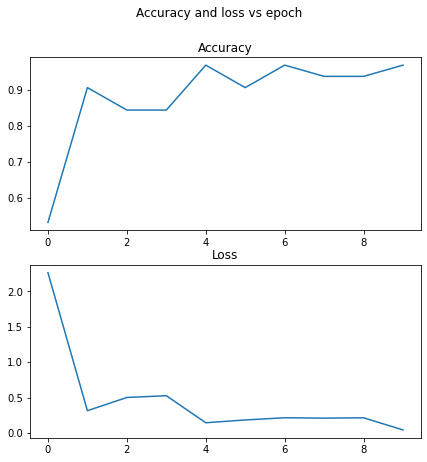

In [8]:
def plot_loss_acc(losses, accuracies):
    fig, axs = plt.subplots(2, figsize=(7, 7))
    fig.suptitle('Accuracy and loss vs epoch')
    axs[0].plot(range(EPOCHS), accuracies)
    axs[1].plot(range(EPOCHS), losses)
    axs[0].title.set_text('Accuracy')
    axs[1].title.set_text('Loss')

    plt.show()
    
plot_loss_acc(losses, accuracies) 

In [9]:
def print_test_acc(model):
    model.eval()

    total, correct = 0, 0
    
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            # Compute the outputs and get prediction label
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = correct / total

    # Print the accuracy
    print('Accuracy on test images: {:.3f}%'.format(accuracy * 100))

print_test_acc(model)

Accuracy on test images: 96.070%


In [ ]:
BATCH_SIZES = [4, 8, 12, 16]
for bs in BATCH_SIZES: 
    print("batch size:", bs)
    train_loader, test_loader = get_dataloader(bs)
    model = CNN()
    model.to(device)
    losses, accuracies = train(model)
    print_test_acc(model)

In [18]:
ACTIVATIONS = [nn.Tanh, nn.Sigmoid, nn.LeakyReLU]
for activation in ACTIVATIONS: 
    print("Using", activation)
    train_loader, test_loader = get_dataloader(BATCH_SIZE)
    model = CNN(activation=activation)
    model.to(device)
    losses, accuracies = train(model)
    print_test_acc(model)

Using <class 'torch.nn.modules.activation.Tanh'>
Epoch [0/10], Step [1874/1875], Loss: 0.400, Accuracy: 87.500%
Epoch [1/10], Step [1874/1875], Loss: 0.157, Accuracy: 96.875%
Epoch [2/10], Step [1874/1875], Loss: 0.492, Accuracy: 87.500%
Epoch [3/10], Step [1874/1875], Loss: 0.239, Accuracy: 90.625%
Epoch [4/10], Step [1874/1875], Loss: 0.270, Accuracy: 87.500%
Epoch [5/10], Step [1874/1875], Loss: 0.249, Accuracy: 90.625%
Epoch [6/10], Step [1874/1875], Loss: 0.175, Accuracy: 93.750%
Epoch [7/10], Step [1874/1875], Loss: 0.240, Accuracy: 90.625%
Epoch [8/10], Step [1874/1875], Loss: 0.375, Accuracy: 87.500%
Epoch [9/10], Step [1874/1875], Loss: 0.102, Accuracy: 96.875%
Accuracy on test images: 93.800%
Using <class 'torch.nn.modules.activation.Sigmoid'>
Epoch [0/10], Step [1874/1875], Loss: 2.283, Accuracy: 15.625%
Epoch [1/10], Step [1874/1875], Loss: 2.296, Accuracy: 15.625%
Epoch [2/10], Step [1874/1875], Loss: 2.303, Accuracy: 15.625%
Epoch [3/10], Step [1874/1875], Loss: 2.312, Ac

In [ ]:
import torch.nn.functional as F
from PIL import Image, ImageOps

imgs = ["test1.png", "test2.png", "test3.png", "test4.png", "test5.png"]
for f in imgs:
    # Load the image and preprocess it
    img = Image.open(PATH + f).convert('L')
    img = img.resize((28, 28))
    img = ImageOps.invert(img)
    
    img_raw = img 
    img = (torch.tensor(img.getdata(), dtype=torch.float32) / 255)
    img = img.view(1, 1, 28, 28)
    # print(img[0].reshape(28,28))
    # break
    img = img.to(device)

    model.eval()

    # Make a prediction and print the result
    with torch.no_grad():
        output = model(img)
        _, predicted = torch.max(output.data, 1)
        plt.imshow(img_raw, cmap="gray")
        plt.title(f"The predicted digit is: {predicted.item()}")
        plt.show()

# 2. Stereo Vision - Epipolar Geometry 

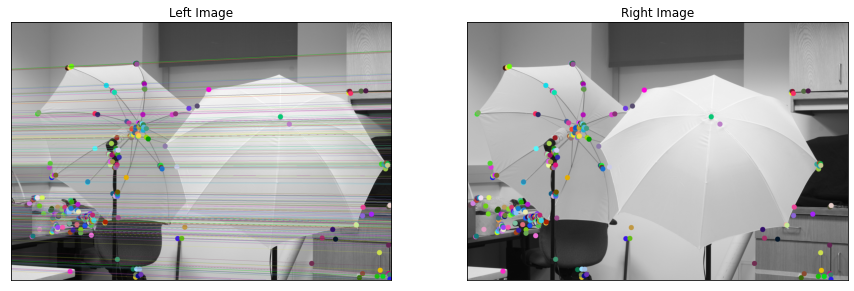

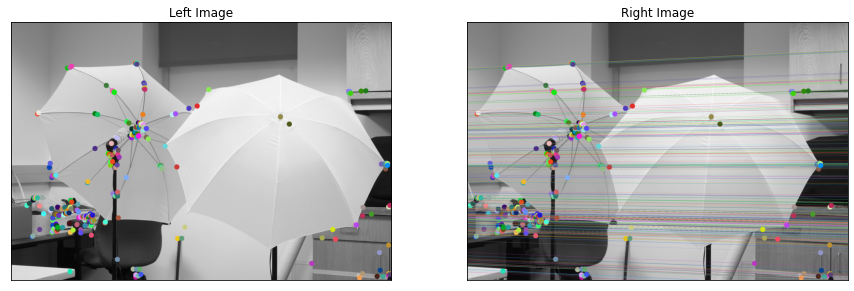

In [54]:
def drawlines(img1, img2, lines, pts1, pts2):
    """
    This function was taken from tutorial 10 of ECSE415
    Draw epilines. Epilines corresponding to the points in 
    the first image are drawn on the second image.
    :param img1: image on which we draw the epilines for the points
            in img2
    :param lines: corresponding epilines
    """
    # img1 shape
    row, col = img1.shape
    # convert from grayscale to BGR
    img1 = cv2.cvtColor(img1, cv2.COLOR_GRAY2BGR)
    img2 = cv2.cvtColor(img2, cv2.COLOR_GRAY2BGR)
    # for each line
    for r, pt1, pt2 in zip(lines, pts1, pts2):
        # pick a random color
        color = tuple(np.random.randint(0, 255, 3).tolist())
        x0, y0 = map(int, [0, -r[2]/r[1]])
        x1, y1 = map(int, [col, -(r[2]+r[0]*col)/r[1]])
        # draw the lines and the points
        img1 = cv2.line(img1, (x0,y0), (x1,y1), color, 1)
        img1 = cv2.circle(img1, tuple(pt1), 20, color, -1)
        img2 = cv2.circle(img2, tuple(pt2), 20, color, -1)
    return img1, img2


img_left = cv2.imread(PATH + "im0.png", cv2.IMREAD_GRAYSCALE)
img_right = cv2.imread(PATH + "im1.png", cv2.IMREAD_GRAYSCALE)

sift = cv2.xfeatures2d.SIFT_create()

# create a Brute-Force Matcher
bfMatcher = cv2.BFMatcher(cv2.NORM_L2)

# find keypoints and descriptors with SIFT
kpL, desL = sift.detectAndCompute(img_left, None)
kpR, desR = sift.detectAndCompute(img_right, None)

matches = bfMatcher.knnMatch(desL, desR, k=2) # query image, train image
# ratio test - store the list of best matches from both images
good = []
ptsL = []
ptsR = []
for i, (m, n) in enumerate(matches):
    if m.distance < 0.6 * n.distance:
        good.append(m)
        ptsR.append(kpR[m.trainIdx].pt)
        ptsL.append(kpL[m.queryIdx].pt)

# find the Fundamental Matrix
ptsL = np.int32(ptsL)
ptsR = np.int32(ptsR)
F, mask = cv2.findFundamentalMat(ptsL, ptsR, cv2.FM_LMEDS) # least-median algorithm

# Use only inliers for remaining computations
ptsL = ptsL[mask.ravel()==1]
ptsR = ptsR[mask.ravel()==1]


# find epilines
# second image
linesL = cv2.computeCorrespondEpilines(ptsR, 2, F)
linesL = linesL.reshape(-1, 3)
# draw lines
imgL1, imgR1 = drawlines(img_left, img_right, linesL, ptsL, ptsR)

linesR = cv2.computeCorrespondEpilines(ptsL, 1, F)
linesR = linesR.reshape(-1, 3)
# draw lines
imgR2, imgL2 = drawlines(img_right, img_left, linesR, ptsR, ptsL)

# display images
plt.figure(figsize=(15,15))
plt.subplot(121), plt.imshow(imgL1, cmap="gray")
plt.title("Left Image"), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgR1, cmap="gray")
plt.title("Right Image"), plt.xticks([]), plt.yticks([])
plt.figure(figsize=(15,15))
plt.subplot(121), plt.imshow(imgL2, cmap="gray")
plt.title("Left Image"), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgR2, cmap="gray")
plt.title("Right Image"), plt.xticks([]), plt.yticks([])
plt.show()

In [22]:
# matched_keypoint = kpL[good[0].queryIdx]
# x, y = int(matched_keypoint.pt[0]), int(matched_keypoint.pt[1])
# patch = img_left[y-2:y+3, x-2:x+3]

In [55]:
match = good[0]
linesL = linesL[match.queryIdx]

# Find the corresponding point in the right image
pt_right = tuple(map(int, kpR[match.trainIdx].pt))

# Compute the coordinates of the closest point on the epipolar line in the right image
x, y = map(int, kpL[match.queryIdx].pt)
a, b, c = linesL
x_epipolar = int((-b*y - c) / a)

# Extract a 5x5 patch around the chosen keypoint in the left image
patch_left = img_left[y-2:y+3, x-2:x+3]

In [63]:
asjdh = img_right[pt_right[1]-2:pt_right[1]+3, x-2:x+3]
asjdh

array([], shape=(5, 0), dtype=uint8)

In [69]:
x_epipolar

-6455

In [67]:
# Match the patch to every 5x5 patch along the epipolar line in the right image
best_match = None
best_score = 0
for x in range(x_epipolar-2, x_epipolar+3):
    print(x)
    patch_right = img_right[pt_right[1]-2:pt_right[1]+3, x-2:x+3]
    print(patch_right)
    patch_right = cv2.cvtColor(patch_right, cv2.COLOR_BGR2GRAY)
    patch_lelft = cv2.cvtColor(patch_lelft, cv2.COLOR_BGR2GRAY)
    
    score = cv2.matchTemplate(patch_left, patch_right, cv2.TM_CCORR_NORMED)[0][0]
    if score > best_score:
        best_score = score
        best_match = (x, pt_right[1])

# Draw a rectangle around the best match
if best_match is not None:
    x, y = best_match
    img_right = cv2.rectangle(img_right, (x-2, y-2), (x+2, y+2), (0, 255, 0), 1)

# Display the results
cv2.imshow('Left image', img_left)
cv2.imshow('Right image', img_right)
cv2.waitKey(0)
cv2.destroyAllWindows()


-6457
[]


NameError: name 'patch_lelft' is not defined

# 3. Motion Algorithm

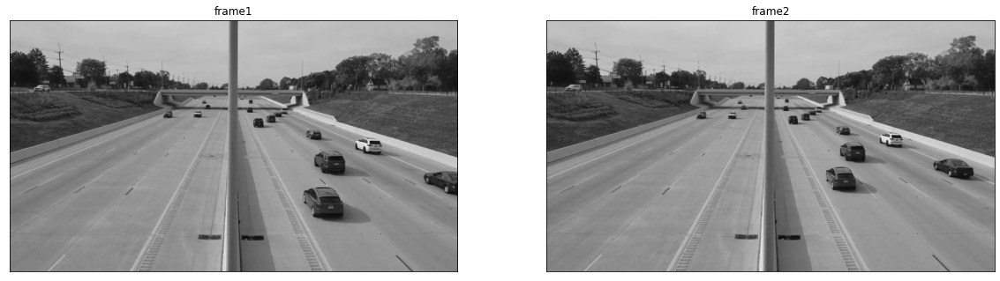

In [3]:
frame1_raw = cv2.imread(PATH+"frame1.png")
frame2_raw = cv2.imread(PATH+"frame2.png")

# convert to grayscale
frame1 = cv2.cvtColor(frame1_raw, cv2.COLOR_BGR2GRAY)
frame2 = cv2.cvtColor(frame2_raw, cv2.COLOR_BGR2GRAY)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
ax1.imshow(frame1, cmap="gray")
ax1.set_title("frame1")
ax2.set_title("frame2")
ax2.imshow(frame2, cmap="gray")
ax1.set_xticks([])
ax1.set_yticks([])
ax2.set_xticks([])
ax2.set_yticks([])

plt.show()

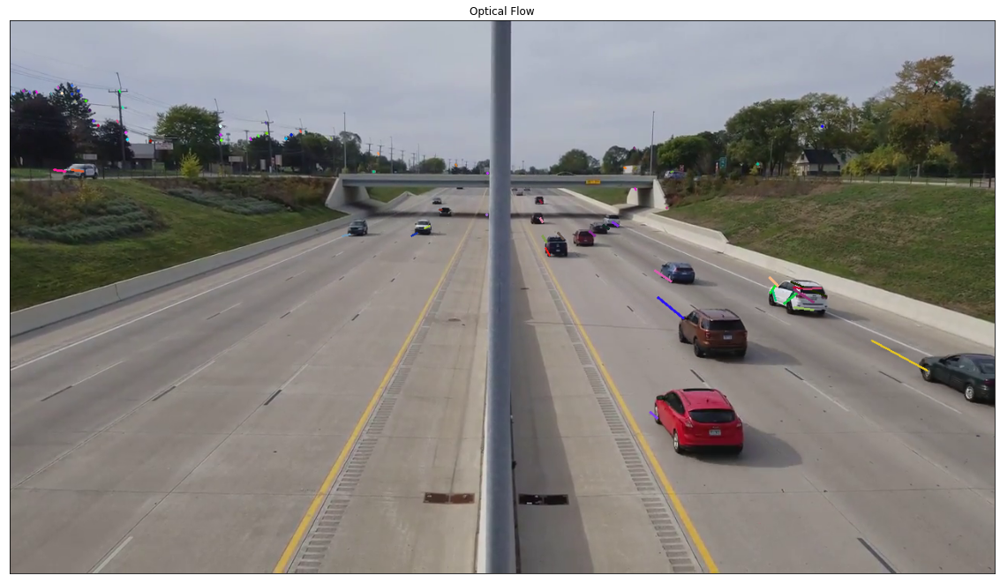

In [4]:
p1 = cv2.goodFeaturesToTrack(frame1, maxCorners=500, qualityLevel=0.26, minDistance=7, blockSize=7)


lk_params = dict( winSize = (15,15),
                  maxLevel = 2,
                  criteria = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
                             10, 0.03))

p2, st, _ = cv2.calcOpticalFlowPyrLK(frame1, frame2, p1, None, **lk_params)

# select good points
good_new = p2[st==1]
good_old = p1[st==1]


def disp_optic_flow(good_new, good_old, title=""):
    # create some random colors
    color = np.random.randint(0, 255, (good_new.shape[0], 3))

    # create a mask image for drawing purposes
    mask = frame1_raw.copy()

    # draw the tracks
    for i, (new, old) in enumerate(zip(good_new, good_old)):
        a, b = new.ravel()
        c, d = old.ravel()
        mask = cv2.line(mask, (int(a),int(b)), (int(c),int(d)), color[i].tolist(), 2)

    # display images
    plt.figure(figsize=(20,20))
    plt.imshow(cv2.cvtColor(mask, cv2.COLOR_BGR2RGB))
    plt.title("Optical Flow" + title), plt.xticks([]), plt.yticks([])
    plt.show()
    
disp_optic_flow(good_new, good_old)

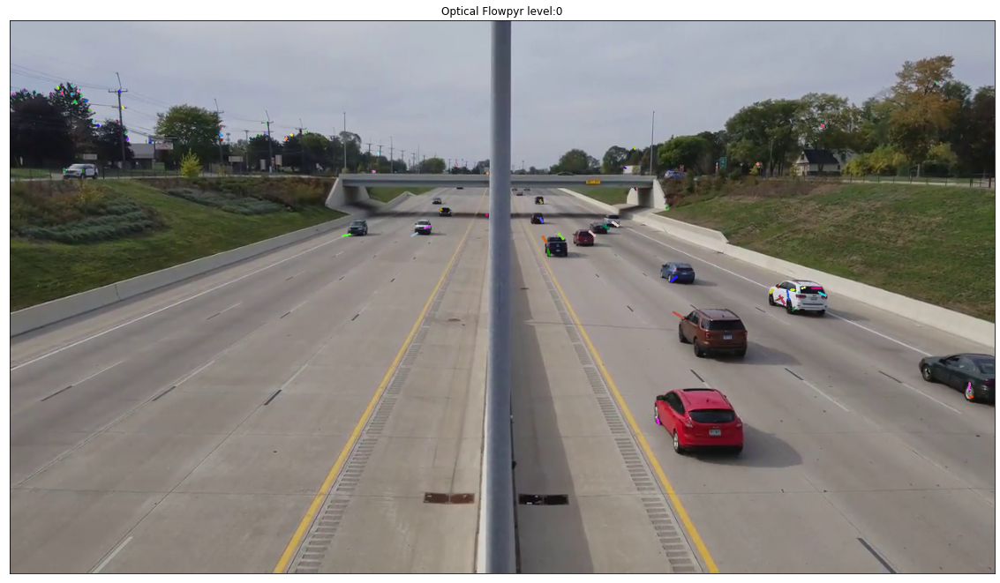

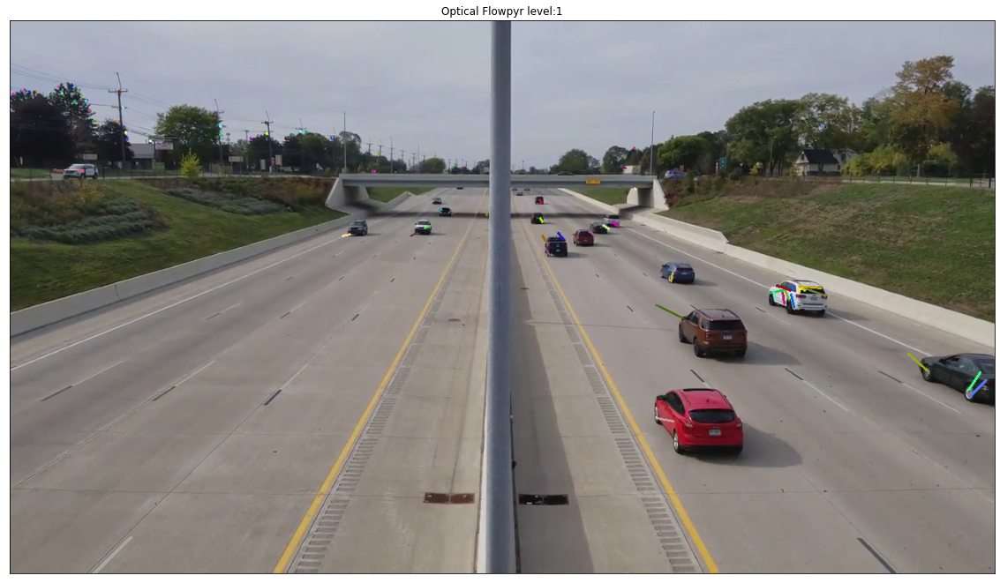

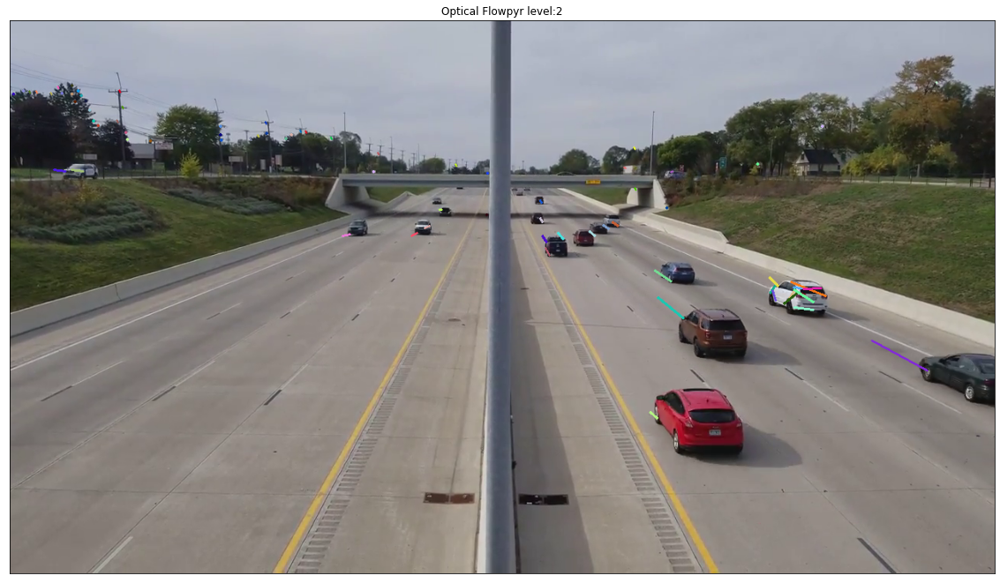

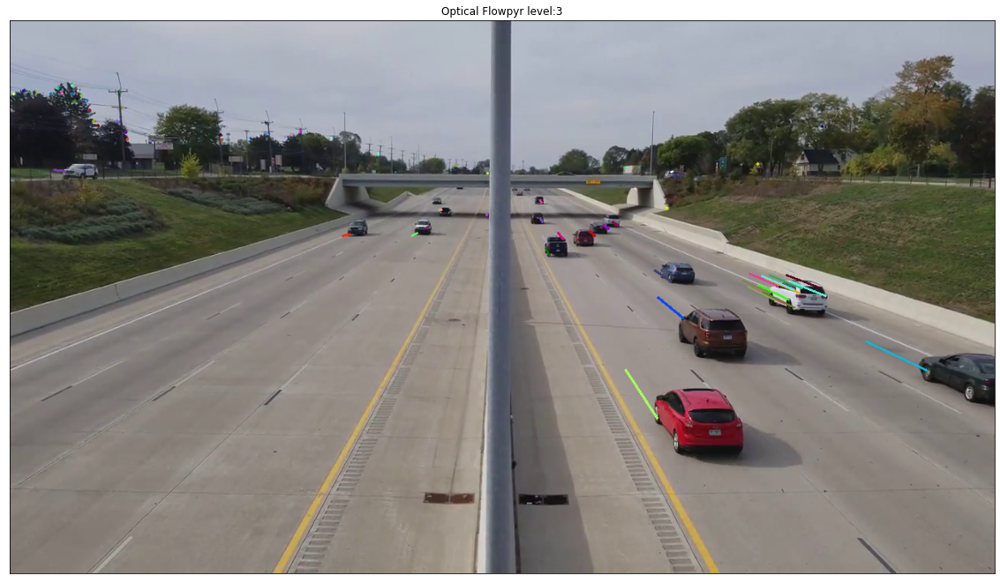

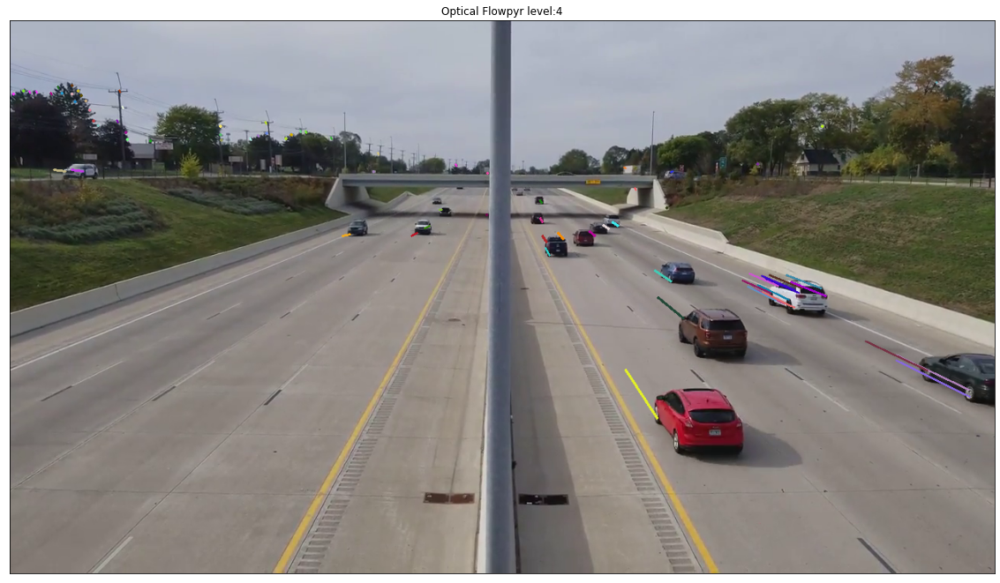

...

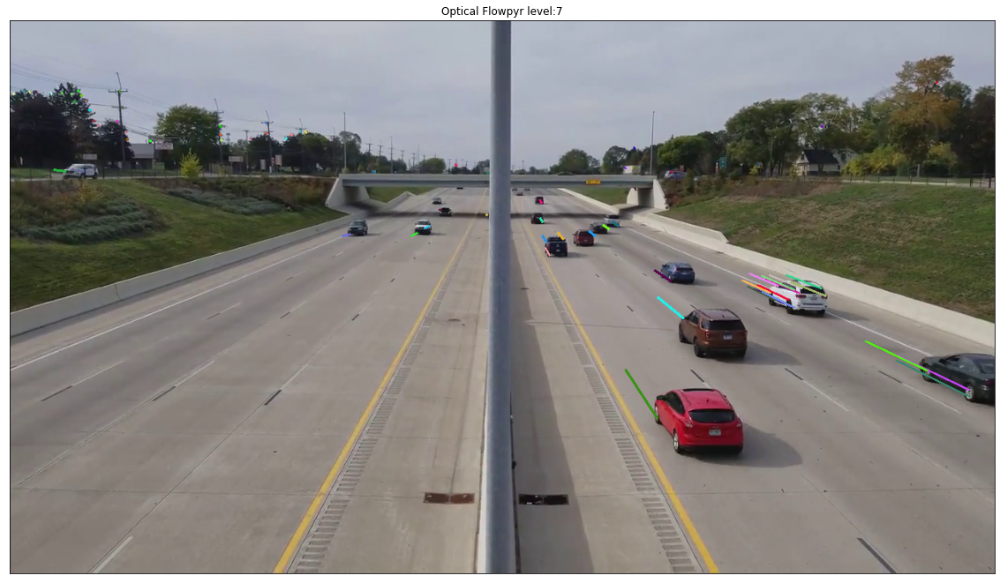

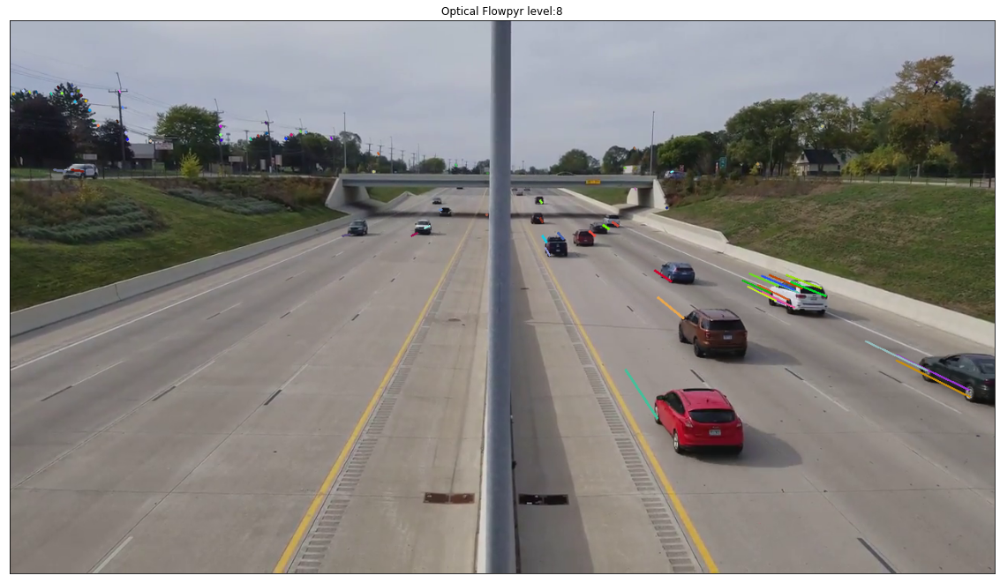

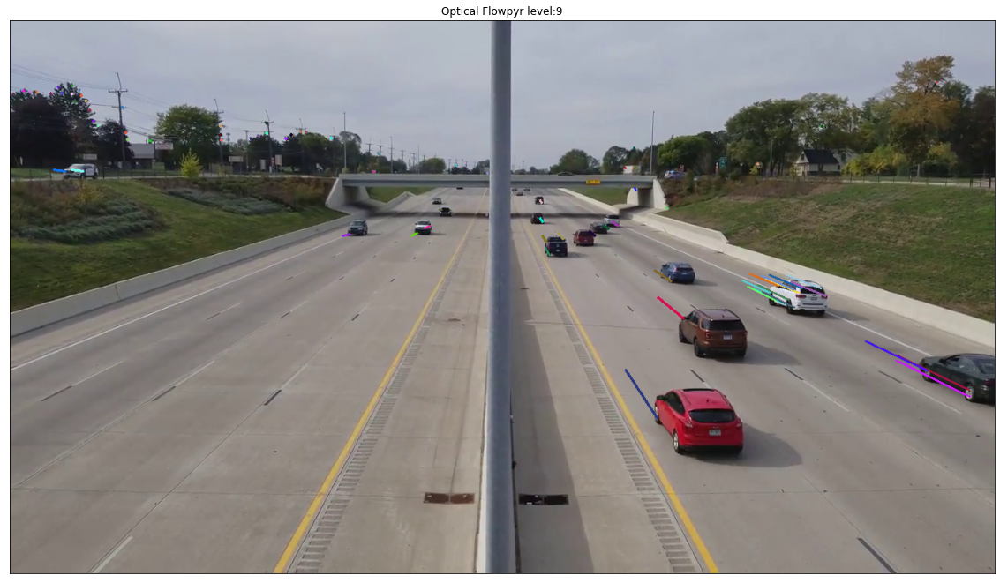

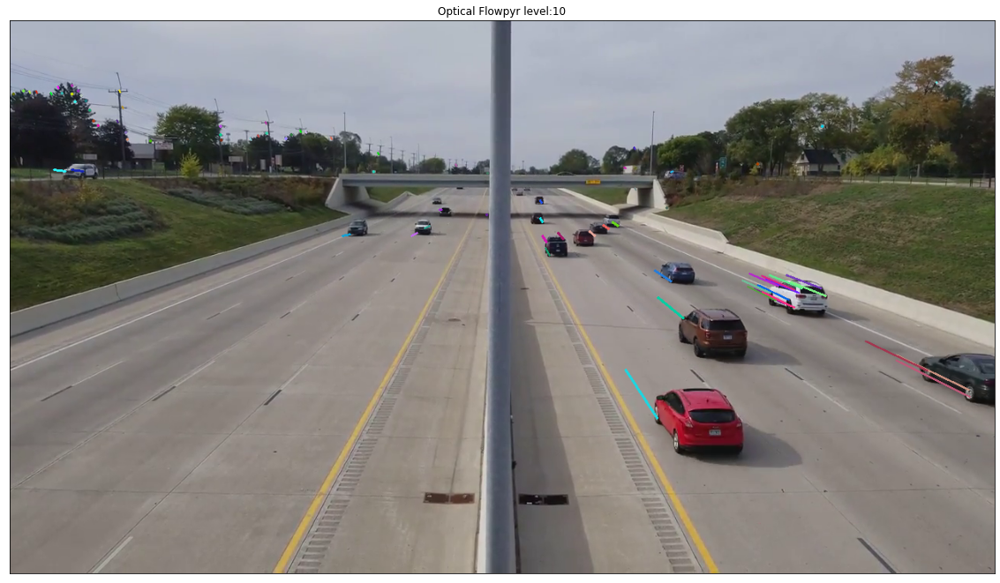

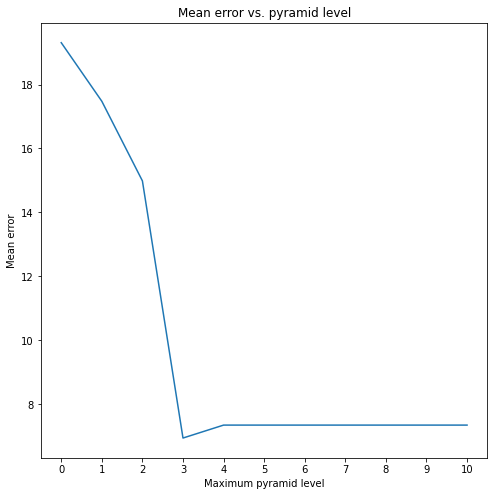

In [9]:
pyr_levels = list(range(0, 11))
mean_err = []
for pyr_level in pyr_levels: 
    lk_params = dict(winSize=(15, 15), maxLevel=pyr_level, criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))
    p2, st, err = cv2.calcOpticalFlowPyrLK(frame1, frame2, p1, None, **lk_params)
    # select good points
    good_new = p2[st==1]
    good_old = p1[st==1]
    
    err = err[st==1]
    
    # Compute the mean error for the successful points
    # errors = np.sqrt(np.sum(np.square(good_new - good_old), axis=1))
    # mean_error = np.mean(errors)
    
    mean_error = np.mean(err)
    mean_err.append(mean_error)
    
    disp_optic_flow(good_new, good_old, title="pyr level:" + str(pyr_level))

plt.figure(figsize=(8, 8))
plt.plot(pyr_levels, mean_err)
plt.title('Mean error vs. pyramid level')
plt.xlabel('Maximum pyramid level')
plt.ylabel('Mean error')
plt.xticks(pyr_levels)
plt.show()
